#pip install pandas numpy matplotlib seaborn scikit-learn joblib

## Importing Libraries & Data Load

In [5]:
import os
import getpass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib

# connect to MySQL, the password is asked when this cell runs
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password=getpass.getpass('MySQL password: '),
    database='db_churn'
)

# training data: customers who have already stayed or churned
data = pd.read_sql("SELECT * FROM vw_ChurnData", conn)
print(data.shape)
print(data.head())

C:\Users\shantanu\AppData\Local\Temp\ipykernel_19400\1501563425.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  data = pd.read_sql("SELECT * FROM vw_ChurnData", conn)


(6007, 32)
  Customer_ID  Gender  Age Married        State  Number_of_Referrals  \
0   19877-DEL    Male   35      No        Delhi                    7   
1   58353-MAH  Female   45     Yes  Maharashtra                   14   
2   25063-WES    Male   51      No  West Bengal                    4   
3   59787-KAR    Male   79      No    Karnataka                    3   
4   28544-TAM  Female   80      No   Tamil Nadu                    3   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
0                27       None           Yes             No  ...   
1                13       None           Yes            Yes  ...   
2                35     Deal 5           Yes             No  ...   
3                21     Deal 4           Yes             No  ...   
4                 8       None           Yes             No  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0      Credit Card           65.6        593.30          0.00   
1      Credit Car

## Data Preprocessing

In [6]:
# cumulative columns grow with time, so they would leak into predictions for new customers
data = data.drop(['Customer_ID', 'Churn_Category', 'Churn_Reason',
                  'Total_Revenue', 'Total_Charges', 'Total_Long_Distance_Charges',
                  'Total_Refunds', 'Total_Extra_Data_Charges', 'Tenure_in_Months'], axis=1)

# List of columns to be label encoded
columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service', 'Multiple_Lines',
    'Internet_Service', 'Internet_Type', 'Online_Security', 'Online_Backup',
    'Device_Protection_Plan', 'Premium_Support', 'Streaming_TV', 'Streaming_Movies',
    'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',
    'Payment_Method'
]

# Encode categorical variables except the target variable
label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    data[column] = label_encoders[column].fit_transform(data[column])

# Manually encode the target variable 'Customer_Status'
data['Customer_Status'] = data['Customer_Status'].map({'Stayed': 0, 'Churned': 1})

# Split data into features and target
X = data.drop('Customer_Status', axis=1)
y = data['Customer_Status']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Train Random Forest Model

Confusion Matrix:
[[777  64]
 [140 221]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88       841
           1       0.78      0.61      0.68       361

    accuracy                           0.83      1202
   macro avg       0.81      0.77      0.78      1202
weighted avg       0.83      0.83      0.82      1202



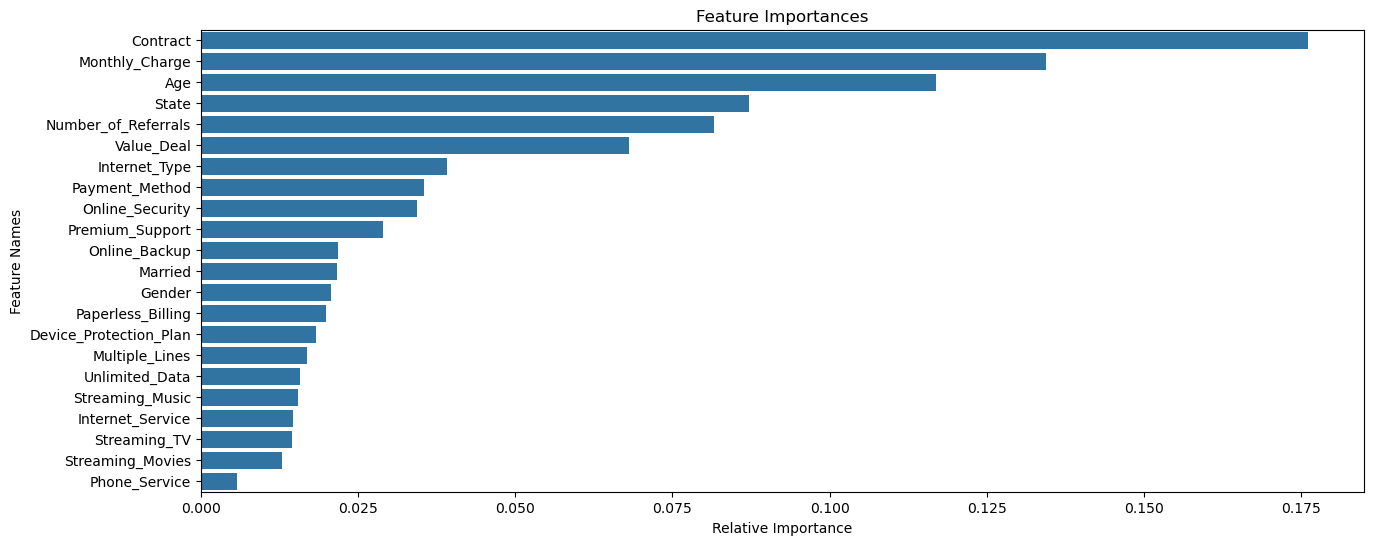

In [7]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Evaluate Model
# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Feature Selection using Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(15, 6))
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()

## Use Model for Prediction on New Data

In [8]:
# new customers whose churn we want to predict
new_data = pd.read_sql("SELECT * FROM vw_JoinData", conn)
print(new_data.shape)

# keep a copy so Customer_ID and the other readable columns stay in the output
original_data = new_data.copy()

# drop the columns the model was not trained on
new_data = new_data.drop(['Customer_ID', 'Customer_Status', 'Churn_Category', 'Churn_Reason','Total_Revenue', 'Total_Charges', 'Total_Long_Distance_Charges','Total_Refunds', 'Total_Extra_Data_Charges', 'Tenure_in_Months'], axis=1)

# convert text columns to numbers with the same encoders used in training
for column in new_data.select_dtypes(exclude=['number']).columns:
    new_data[column] = label_encoders[column].transform(new_data[column])

# 1 means likely to churn, 0 means likely to stay
new_predictions = rf_model.predict(new_data)
original_data['Customer_Status_Predicted'] = new_predictions

# keep only the customers predicted to churn
original_data = original_data[original_data['Customer_Status_Predicted'] == 1]
print("Predicted churners:", len(original_data))

# this file is loaded into the Power BI prediction page
original_data.to_csv(r"C:\Users\shantanu\Downloads\Predictions.csv", index=False)
conn.close()

(411, 32)
Predicted churners: 129


C:\Users\shantanu\AppData\Local\Temp\ipykernel_19400\4184980009.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  new_data = pd.read_sql("SELECT * FROM vw_JoinData", conn)
